In [1]:
import datetime
import pandas as pd

# from polygon import RESTClient
from os import listdir
import pickle

from experiment_main import *
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

# API_KEY = "4c0LGxg6J6xl50lzMD9wMyG_pT4o33_I"
# client = RESTClient(api_key=API_KEY)

plt.style.use("plot_style.txt")

alpha_range = [
    -0.9,
    -0.8,
    -0.7,
    -0.6,
    -0.5,
    -0.4,
    -0.3,
    -0.2,
    -0.1,
    0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
]
gamma_range = [
    1,
    2,
    4,
    10,
    20,
    30,
    40,
    50,
    60,
    70,
    80,
    90,
    100,
    200,
    300,
    400,
    500,
    600,
    700,
    800,
    900,
    1000,
    10000,
    100000,
]
gamma_range_reversed = list(reversed(gamma_range))
gen = [(x, y) for x in alpha_range for y in gamma_range]
histogramList, MACDList, signalLineList = return_macd_lists(alpha_range, gamma_range)

In [2]:
market = "stocks"
macd_params = (12, 26, 9)
trade_cost = False
time_format = "1_day"
prefix = f"./data/{market}/{time_format}/"
datafiles = listdir(prefix)
datafiles.remove("meta.us.txt")
datafiles.remove("fb.us.txt")
# makeDataFrame(prefix, datafiles[0], macd_params, alpha_range, gamma_range)
# datafiles

In [3]:
# time_formats = ['1_day', '1_hour', '5_minute', '1_minute']
def get_heatmap_data(
    time_format, gen, datafiles, macd_params, alpha_range, gamma_range
):
    times_dict = {time_format: {k: 0 for k in gen}}
    prefix = f"./data/{market}/{time_format}/"
    for tick in datafiles:
        # print(tick)
        df = make_dataframe(
            prefix, tick, time_format, macd_params, alpha_range, gamma_range,
            # this notebook builds its own ./data/{market}/{time_format}/ prefix,
            # so it reads what that points at, not the near-close collapse
            near_close=False,
        )
        target_cols = [c for c in df.columns if c.endswith("times")]
        for col in target_cols:
            target_tuple = (float(col.split()[2]), int(col.split()[4]))
            times_dict[time_format][target_tuple] += int(df[col].iloc[0])
    data_list = []
    gamma_range_reversed = list(reversed(gamma_range))
    for gamma in gamma_range_reversed:
        for alpha in alpha_range:
            target_tuple = (alpha, gamma)
            data_list.append(times_dict[time_format][target_tuple])
    time_format_max = max(data_list)
    norm_data_list = [float(i) / time_format_max for i in data_list]
    data_plot_time_format = np.array(norm_data_list).reshape(
        (len(gamma_range), len(alpha_range))
    )
    return data_plot_time_format, data_list


def get_heatmap_data_minute(
    time_format, gen, datafiles, macd_params, alpha_range, gamma_range
):
    # short_period, long_period, signal_period = macd_params
    isMonth = "week"
    time_value = 8
    times_dict = {time_format: {k: 0 for k in gen}}
    prefix = f"./data/{market}/{time_format}/"
    for tick in datafiles:
        # print(tick)
        df_read = read_and_change_data(prefix, tick)
        index_list = list(df_read.index)
        # start = df_read.iloc[0].name
        end = df_read.iloc[-1].name

        nan_indexes = (max(macd_params[0], macd_params[1]) + macd_params[2]) - 2

        period_start = df_read.iloc[nan_indexes].name
        period_end = make_new_time(period_start, time_value, isMonth)

        while period_end <= end:

            # test_period_start_index = index_list.index(test_period_start)
            period_start_index = get_index(index_list, period_start)
            calculate_period_start = df_read.iloc[period_start_index - nan_indexes].name
            calculate_period_end = period_end

            df = calculate_indicators(
                df_read[calculate_period_start:calculate_period_end],
                col="close",
                ema_mode="normal",
                short_period=macd_params[0],
                long_period=macd_params[1],
                signal_period=macd_params[2],
                alpha_range=alpha_range,
                gamma_range=gamma_range,
            )
            target_cols = [c for c in df.columns if c.endswith("times")]
            for col in target_cols:
                target_tuple = (float(col.split()[2]), int(col.split()[4]))
                times_dict[time_format][target_tuple] += int(df[col].iloc[0])

            period_start = period_end
            period_end = make_new_time(period_end, time_value, isMonth)

    data_list = []
    gamma_range_reversed = list(reversed(gamma_range))
    for gamma in gamma_range_reversed:
        for alpha in alpha_range:
            target_tuple = (alpha, gamma)
            data_list.append(times_dict[time_format][target_tuple])
    time_format_max = max(data_list)
    norm_data_list = [float(i) / time_format_max for i in data_list]
    data_plot_time_format = np.array(norm_data_list).reshape(
        (len(gamma_range), len(alpha_range))
    )
    return data_plot_time_format, data_list

In [ ]:
# data_plot_1day, data_list_1day = get_heatmap_data('1_day', gen, datafiles, macd_params, alpha_range, gamma_range)
# with open('outfile_1day', 'wb') as fp:
#     pickle.dump(data_plot_1day, fp)
# with open('outfile_1day_raw', 'wb') as fp:
#     pickle.dump(data_list_1day, fp)

with open("outfile_1day", "rb") as fp:
    data_plot_1day = pickle.load(fp)
with open("outfile_1day_raw", "rb") as fp:
    data_list_1day = pickle.load(fp)

In [ ]:
# data_plot_1hour, data_list_1hour = get_heatmap_data('1_hour', gen, datafiles, macd_params, alpha_range, gamma_range)
# with open('outfile_1hour', 'wb') as fp:
#     pickle.dump(data_plot_1hour, fp)
# with open('outfile_1hour_raw', 'wb') as fp:
#     pickle.dump(data_list_1hour, fp)

with open("outfile_1hour", "rb") as fp:
    data_plot_1hour = pickle.load(fp)
with open("outfile_1hour_raw", "rb") as fp:
    data_list_1hour = pickle.load(fp)

In [ ]:
# data_plot_5minute, data_list_5minute = get_heatmap_data_minute('5_minute', gen, datafiles, macd_params, alpha_range, gamma_range)
# with open('outfile_5minute', 'wb') as fp:
#     pickle.dump(data_plot_5minute, fp)
# with open('outfile_5minute_raw', 'wb') as fp:
#     pickle.dump(data_list_5minute, fp)

with open("outfile_5minute", "rb") as fp:
    data_plot_5minute = pickle.load(fp)
with open("outfile_5minute_raw", "rb") as fp:
    data_list_5minute = pickle.load(fp)

In [8]:
def heatmap(
    data,
    row_labels,
    col_labels,
    ax=None,
    cbar_kw={},
    cbarlabel="",
    cbar_return=True,
    **kwargs,
):
    """
    Create a heatmap from a numpy array and two lists of labels.

    Parameters
    ----------
    data
        A 2D numpy array of shape (M, N).
    row_labels
        A list or array of length M with the labels for the rows.
    col_labels
        A list or array of length N with the labels for the columns.
    ax
        A `matplotlib.axes.Axes` instance to which the heatmap is plotted.  If
        not provided, use current axes or create a new one.  Optional.
    cbar_kw
        A dictionary with arguments to `matplotlib.Figure.colorbar`.  Optional.
    cbarlabel
        The label for the colorbar.  Optional.
    **kwargs
        All other arguments are forwarded to `imshow`.
    """

    if not ax:
        ax = plt.gca()

    # Plot the heatmap
    im = ax.imshow(data, **kwargs)

    # Create colorbar
    ticks = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
    # ticks = [-0.5, 0, 1.0]
    cbar = ax.figure.colorbar(im, ax=ax, ticks=ticks, **cbar_kw)
    cbar.ax.set_yticklabels(
        labels=cbar.ax.get_yticklabels(), color="black", weight="bold"
    )
    # cbar = mpl.colorbar.ColorbarBase(
    #     im, ax=ax, orientation='vertical', norm=plt.Normalize(0,1), **cbar_kw
    # )
    # cbar.set_ticks(ticks)
    # cbar.ax.set_yticklabels(ticks)
    # cbar.ax.set_xticklabels(ticks)
    # cbar.ax.set_ylabel(cbarlabel, rotation=-90, va="bottom")
    # .set_ticklabel

    # Show all ticks and label them with the respective list entries.
    ax.set_xticks(
        range(len(col_labels)),
        labels=col_labels,
        color="black",
        weight="bold",
        ha="right",
        rotation=90,
    )

    ax.set_xticklabels(col_labels, fontsize=5)
    ax.set_yticks(
        range(len(row_labels)), labels=row_labels, color="black", weight="bold"
    )
    ax.set_yticklabels(row_labels, fontsize=5)
    # ax.set_yticklabels(avg_y_ticks, weight='bold', color='black')
    # colorbar.set_ticks(np.linspace(0, ncolors, ncolors))
    # colorbar.set_ticklabels(range(ncolors))

    ax.tick_params(
        axis="both",
        which="both",
        right=True,
        left=True,
        labelleft=True,
        labelright=True,
        top=False,
        bottom=True,
        labeltop=False,
        labelbottom=True,
        length=0,
    )

    # Rotate the tick labels and set their alignment.
    plt.setp(ax.get_xticklabels(), ha="center")

    # Turn spines off and create white grid.
    ax.spines[:].set_visible(False)

    return im, cbar


def annotate_heatmap(
    im,
    data=None,
    valfmt="{x:.2f}",
    textcolors=("black", "black"),
    threshold=None,
    **textkw,
):
    """
    A function to annotate a heatmap.

    Parameters
    ----------
    im
        The AxesImage to be labeled.
    data
        Data used to annotate.  If None, the image's data is used.  Optional.
    valfmt
        The format of the annotations inside the heatmap.  This should either
        use the string format method, e.g. "$ {x:.2f}", or be a
        `matplotlib.ticker.Formatter`.  Optional.
    textcolors
        A pair of colors.  The first is used for values below a threshold,
        the second for those above.  Optional.
    threshold
        Value in data units according to which the colors from textcolors are
        applied.  If None (the default) uses the middle of the colormap as
        separation.  Optional.
    **kwargs
        All other arguments are forwarded to each call to `text` used to create
        the text labels.
    """

    if not isinstance(data, (list, np.ndarray)):
        data = im.get_array()

    # Normalize the threshold to the images color range.
    if threshold is not None:
        threshold = im.norm(threshold)
    else:
        threshold = im.norm(data.max()) / 2.0

    # Set default alignment to center, but allow it to be
    # overwritten by textkw.
    kw = dict(horizontalalignment="center", verticalalignment="center")
    kw.update(textkw)

    # Get the formatter in case a string is supplied
    if isinstance(valfmt, str):
        valfmt = mpl.ticker.StrMethodFormatter(valfmt)

    # Loop over the data and create a `Text` for each "pixel".
    # Change the text's color depending on the data.
    texts = []
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            kw.update(color=textcolors[int(im.norm(data[i, j]) > threshold)])
            text = im.axes.text(j, i, valfmt(data[i, j], None), **kw)
            texts.append(text)

    return texts


def plot_times_heatmap(data_list, time_format):

    fig, ax = plt.subplots()

    # Replicate the above example with a different font size and colormap.

    im, cbar = heatmap(
        data_list,
        gamma_range_reversed,
        alpha_range,
        ax=ax,
        cmap="jet",
        cbar_kw={"location": "right", "pad": 0.07},
    )
    im.set_clim([0, 1])
    for l in cbar.ax.yaxis.get_ticklabels():
        l.set_weight("bold")
        l.set_color("black")
    annotate_heatmap(im, valfmt="{x:.3f}", size=4)

    # Create some new data, give further arguments to imshow (vmin),
    # use an integer format on the annotations and provide some colors.
    # cbarlabel="Something ax2"

    fig.tight_layout()
    # plt.subplots_adjust(wspace=0, hspace=0.35)
    # fig.supylabel('Price ($)', fontweight='bold', color='black', fontsize=8)
    time_format_split = time_format.split("_")
    unit_time, resolution_time = time_format_split[0], time_format_split[1].capitalize()
    fig.suptitle(
        f"Window function activation map from 2020-02-06 to 2025-02-06 for {unit_time} {resolution_time} timeformat",
        y=1.02,
        fontweight="bold",
        fontsize=8,
        color="black",
    )
    fig.set_size_inches(5, 5)
    plt.savefig(f"heat_{time_format}.pdf", bbox_inches="tight")

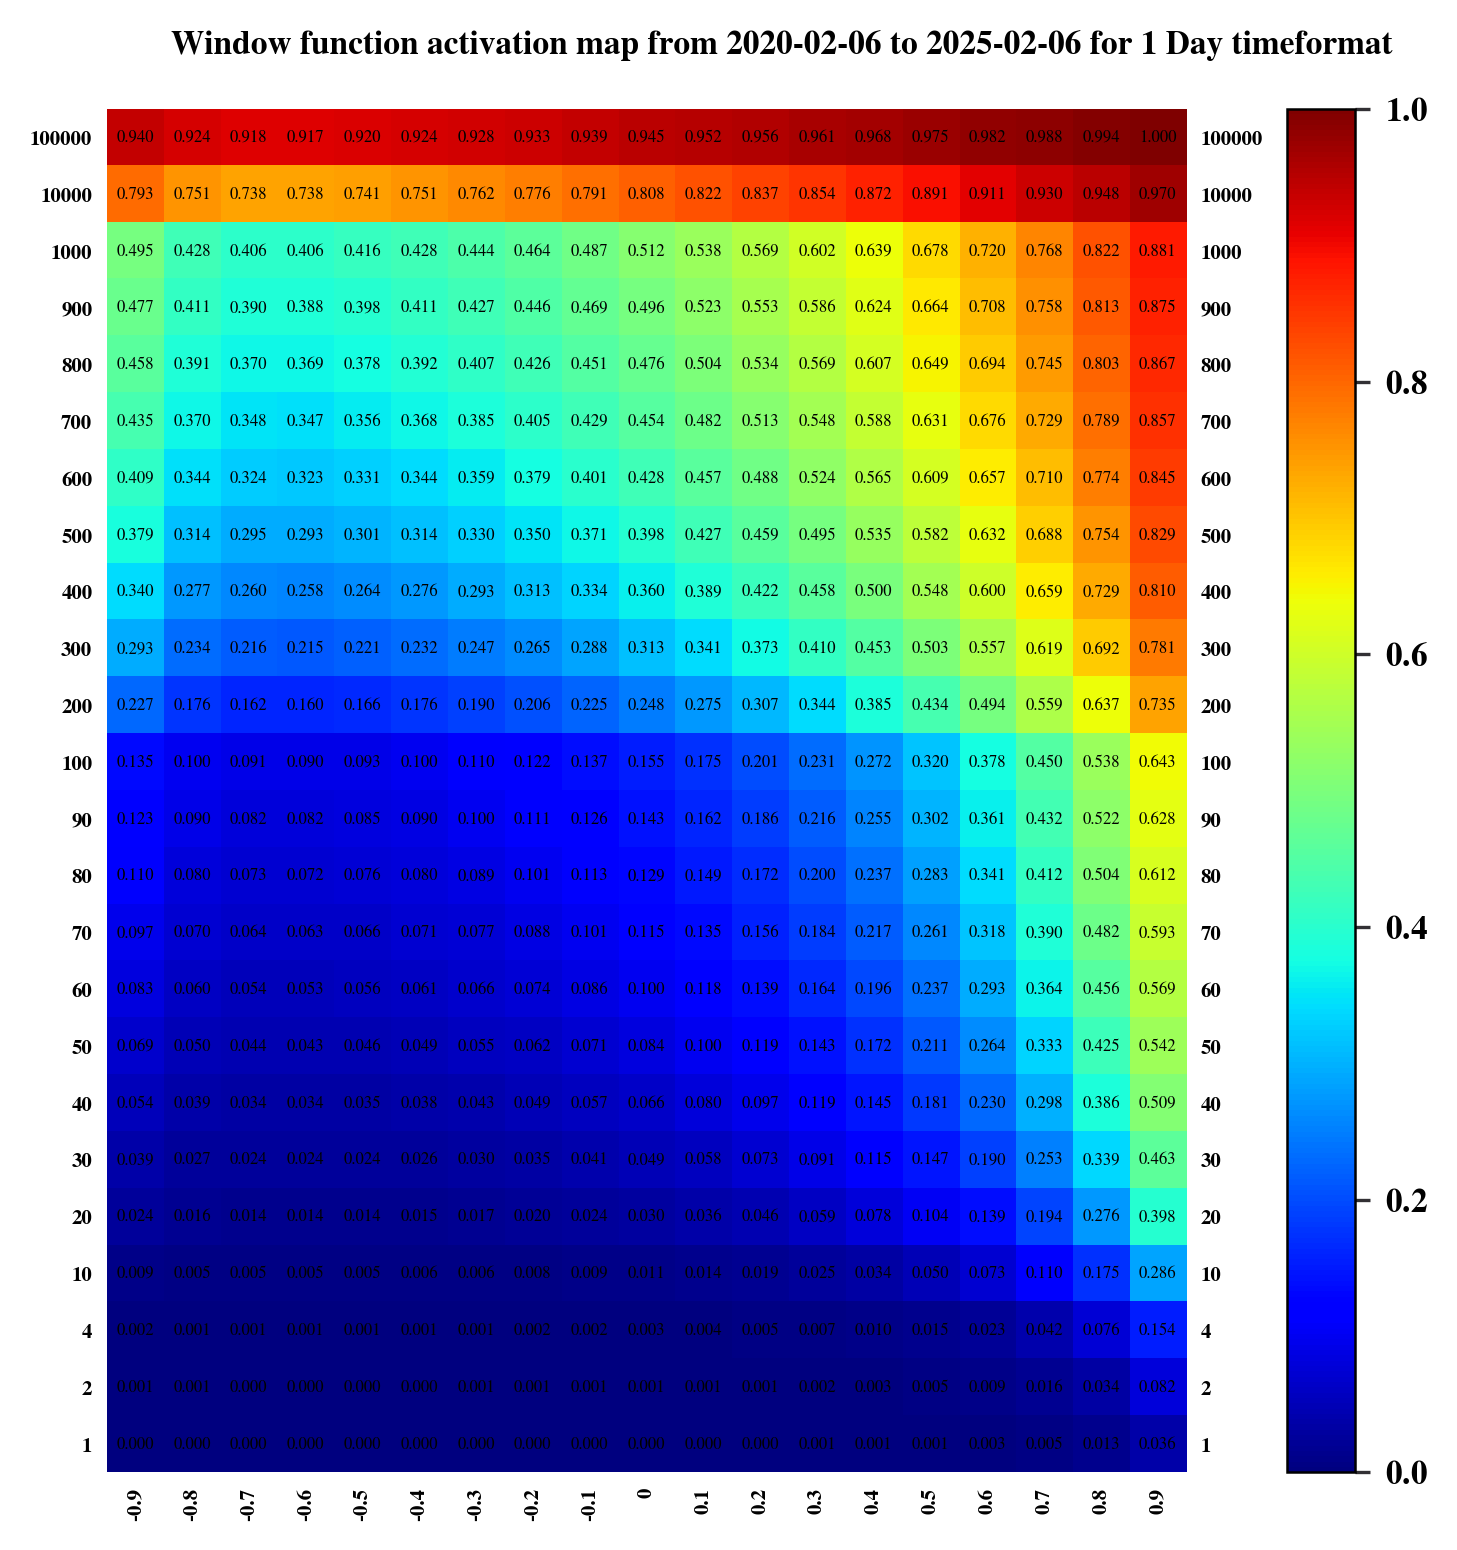

In [9]:
time_format = "1_day"
plot_times_heatmap(data_plot_1day, time_format)

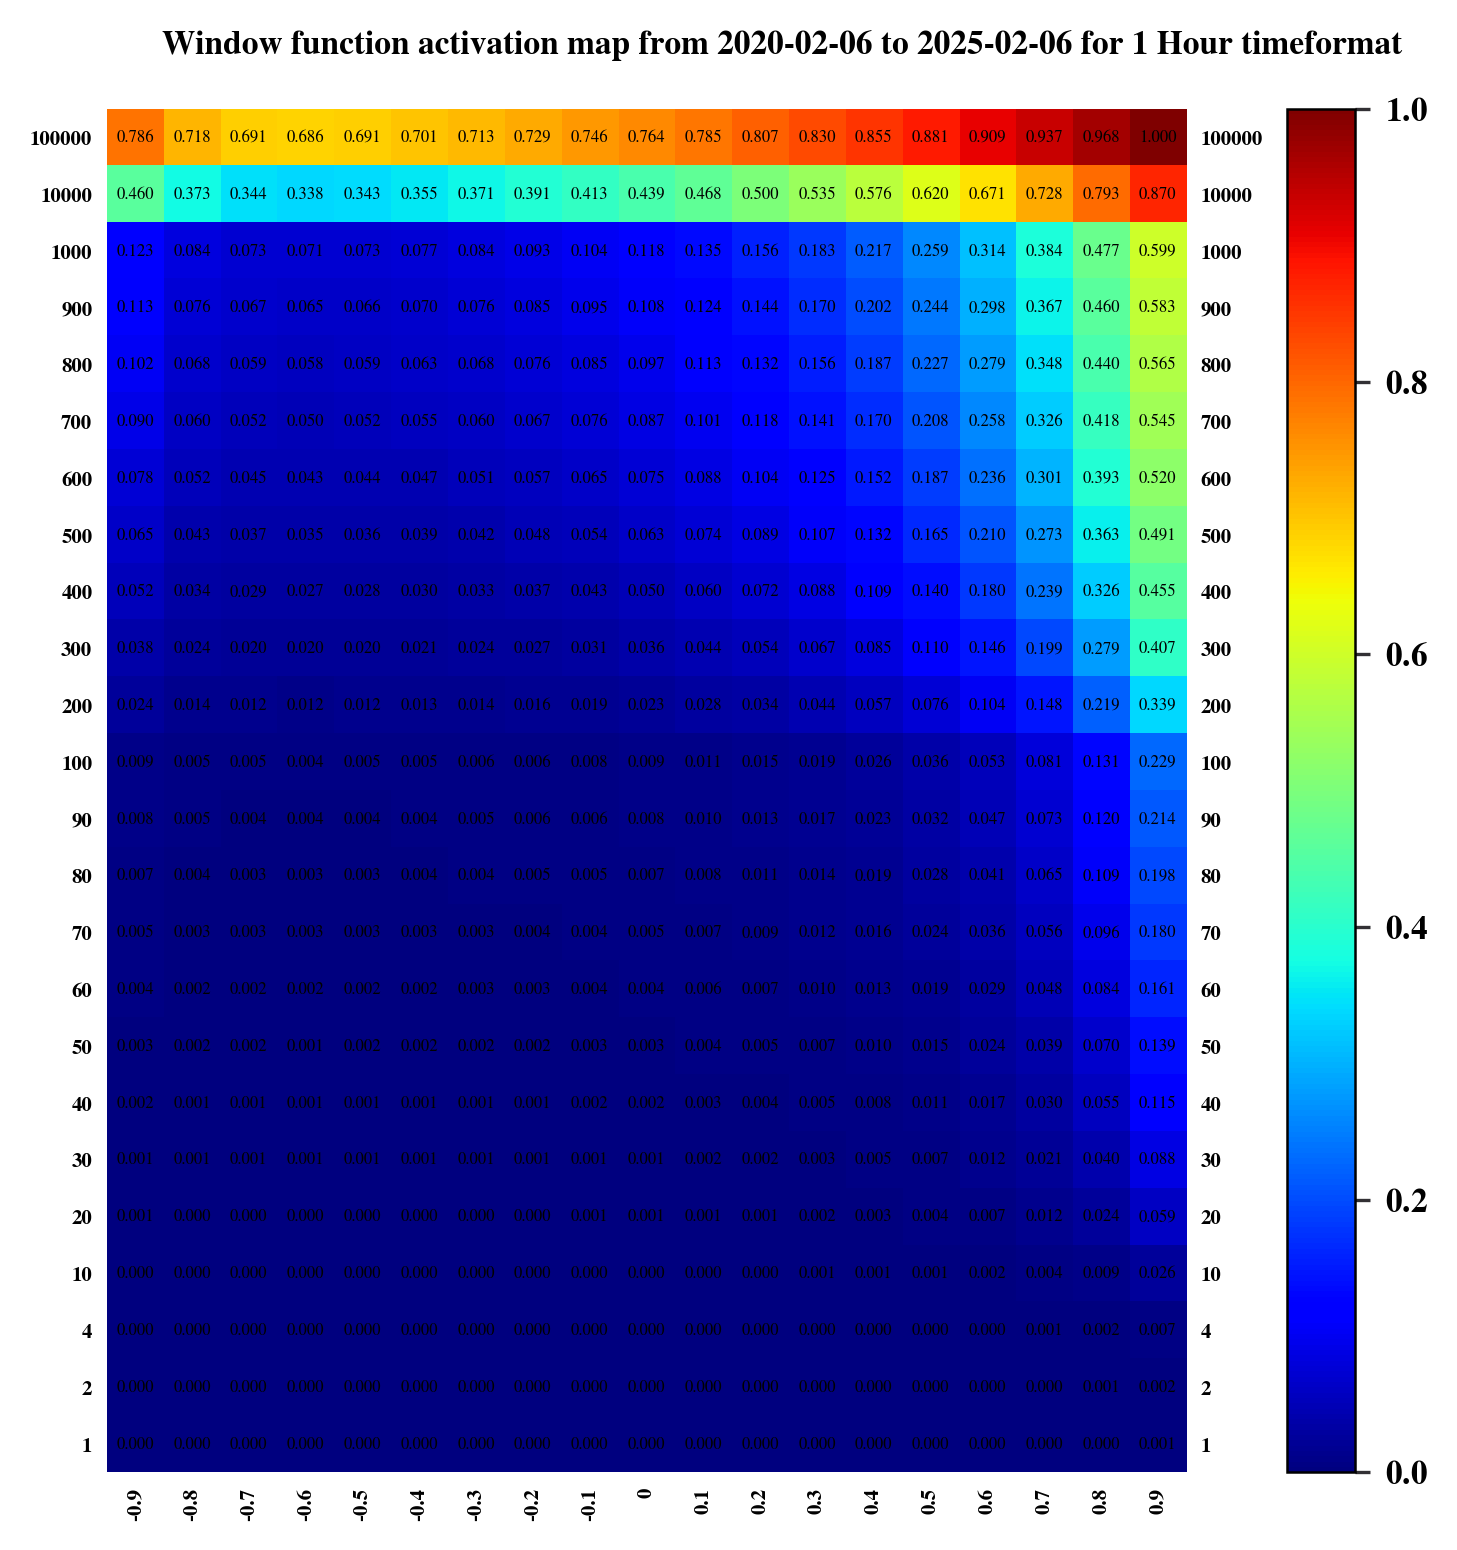

In [10]:
time_format = "1_hour"
plot_times_heatmap(data_plot_1hour, time_format)

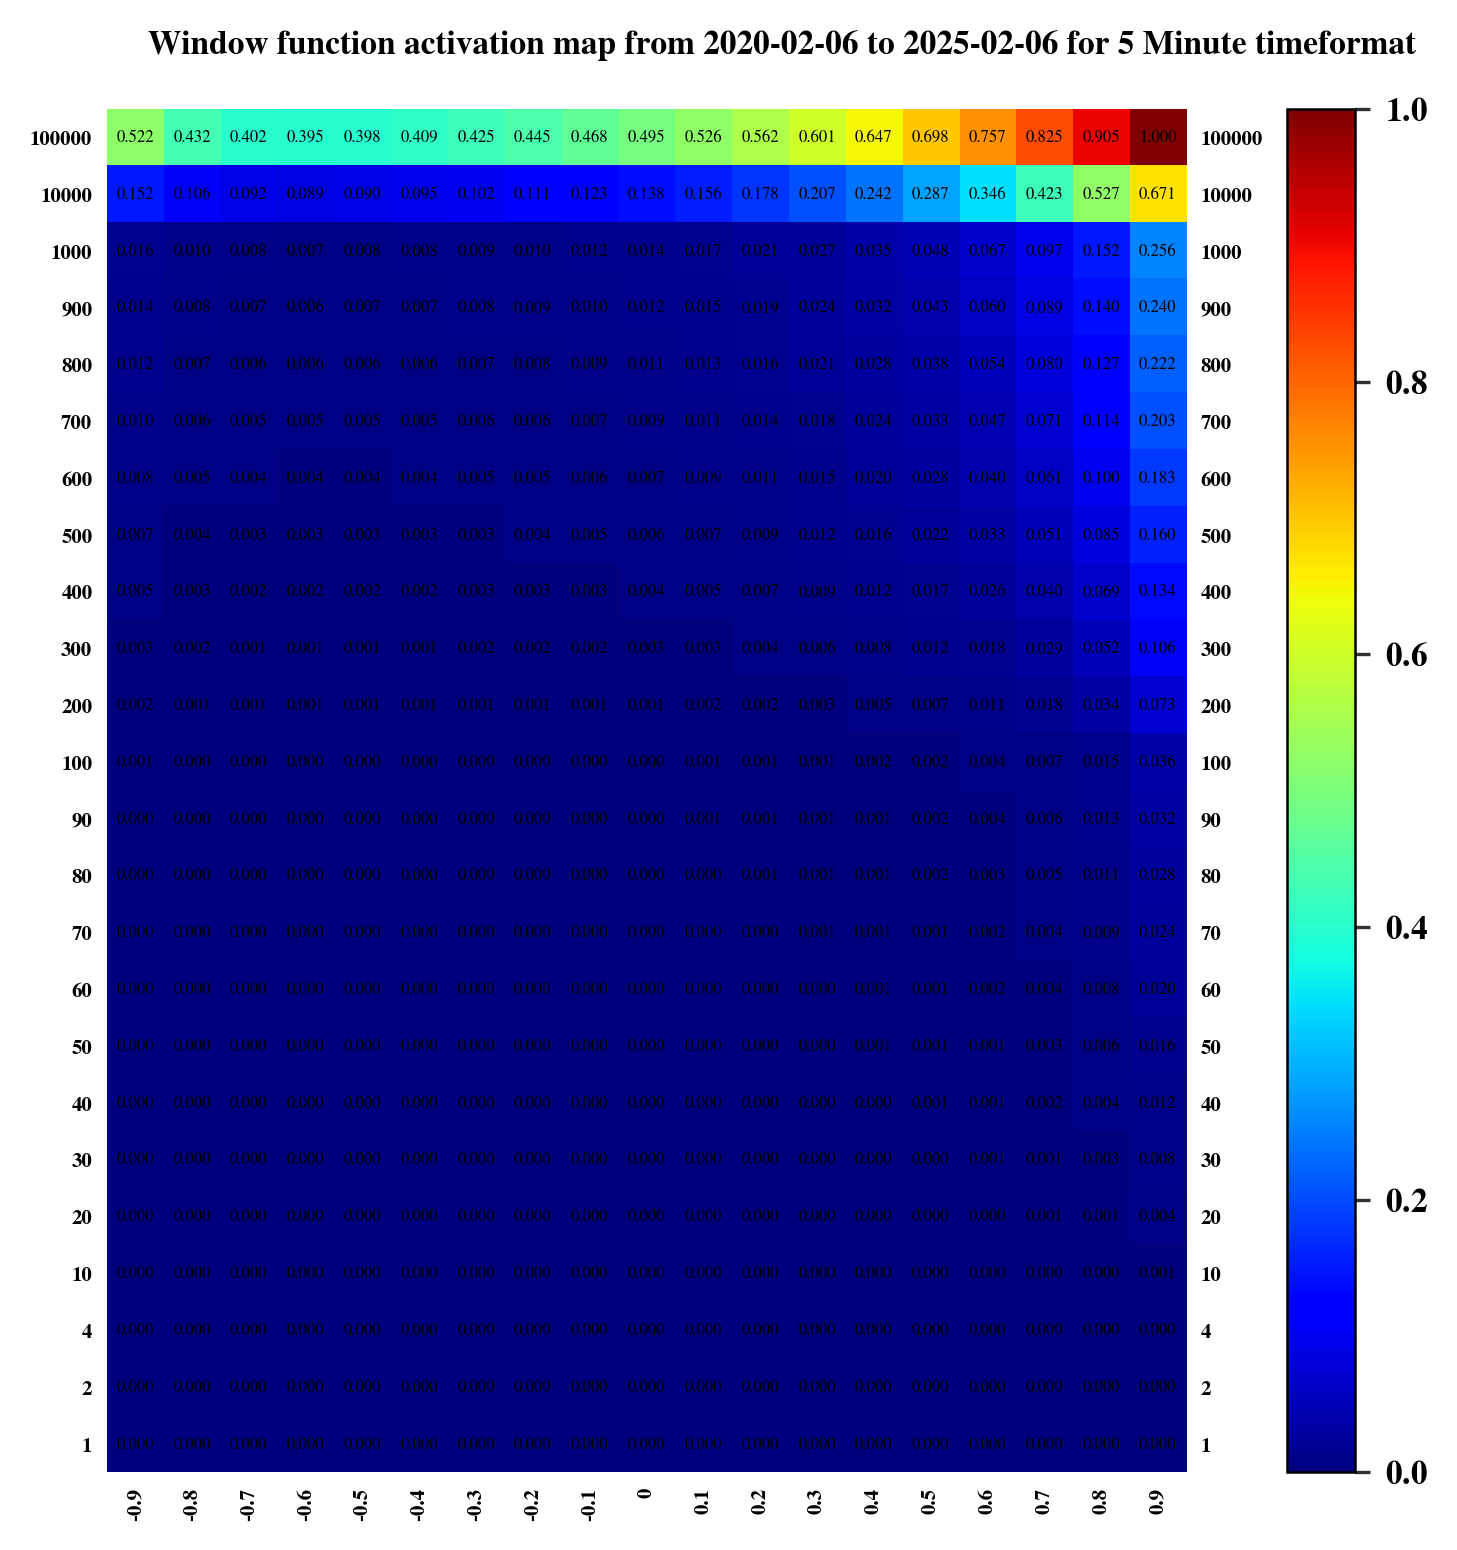

In [11]:
time_format = "5_minute"
plot_times_heatmap(data_plot_5minute, time_format)

In [12]:
# time_format = "1_minute"
# plot_times_heatmap(data_plot_1minute, time_format)